# One decision a week — the brief's literal reading

The brief asks for a model that predicts *"the optimal action (Buy, Sell, or Hold) … over a defined future horizon (e.g., the next 5 trading days)"*. Every version so far makes that prediction **every day** and acts on it daily, so neighbouring 5-day windows overlap. This notebook re-runs every version with **one decision a week**:

> After the close on the last trading day of the week (normally Friday), the model predicts Buy, Hold or Sell for the next 5 trading days. The trade fills at the next open (normally Monday), and the position is held all week. **Buy** → invested, **Sell** → cash, **Hold** → keep last week's position.

**What does not change:** the models, their settings, the labels, the costs and the cash assumptions. Every model is used exactly as frozen. v1 and v2 use their saved test predictions; v3 and the walk-forward recompute the same frozen fits. Only the decision schedule changes.

**Disclosure.** This check was decided **after** all test results were known. It is a sensitivity analysis on already-seen data, not a new selection: no model, threshold or rule is chosen from it. Each daily row first reproduces the published result exactly, so the weekly row differs only by schedule.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, v2, v3, weekly
from src.backtest import to_positions
from src.data import load_snapshot
from src.dataset import build_dataset_v2

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = config.OUTPUT_DIR / "weekly"; (OUT / "figures").mkdir(parents=True, exist_ok=True)

raw = load_snapshot(); px = raw[["Open", "Close"]]
rf = v2.load_tbill_daily(raw.index)
HOLD = config.ROOT / "data" / "holdout"
raw_h = pd.read_csv(HOLD / "spy_20261013.csv", index_col=0, parse_dates=True); px_h = raw_h[["Open", "Close"]]
rf_h = v2.load_tbill_daily(raw_h.index, HOLD / "irx_20261013.csv")

ROWS, PATHS = [], {}
def run(version, period, schedule, held, prices, rf_seg, cash, random_n=1000):
    sim = v2.simulate(held, prices.loc[held.index], rf_seg)
    s = v2.summarize(sim, held, rf_seg, "")
    pct = None
    if s["round_trips"] > 1 and random_n:
        rand = v2.random_timing_benchmark(held, prices.loc[held.index], rf_seg, n=random_n)
        pct = round(float((rand < sim["value"].iloc[-1]).mean()), 3)
    decisions = len(weekly.week_end_days(held.index)) if schedule == "weekly" else len(held)
    ROWS.append({"version": version, "period": period, "schedule": schedule, "cash": cash,
                 "final_value": s["final_value"], "round_trips": s["round_trips"], "exposure": s["exposure"],
                 "fees": s["total_fees"], "sharpe_excess": s["sharpe_excess"], "max_drawdown": s["max_drawdown"],
                 "beats_random_pct": pct, "decision_days": decisions})
    PATHS[(version, period, schedule)] = sim["value"]
    return s["final_value"]

def bh(period, prices, rf_seg, cash, index):
    held = v2.buy_and_hold_held(index)
    return run("Buy & Hold", period, "—", held, prices, rf_seg, cash, random_n=0)

## v1 · random forest, Buy/Sell rule
v1 as built let cash earn 0%. We first reproduce that, then score v1 with cash earning T-bills, like v2 and v3 (one of our improvements over v1).

In [2]:
for period, f in [("2021–22 validation", "val_predictions.csv"), ("2023–24 test", "test_predictions.csv")]:
    pr = pd.read_csv(config.OUTPUT_DIR / f, index_col=0, parse_dates=True)
    daily = v2.held_from_positions(to_positions(pr["action"], min_hold=5))
    as_built = v2.simulate(daily, px.loc[pr.index])["value"].iloc[-1]   # cash at 0%, as in v1
    print(period, f"v1 as built (cash 0%) reproduced: ${as_built:,.0f}")
    if period == "2023–24 test":
        assert round(as_built) == 123714, "v1 must reproduce its published $123,714"
    week = v2.held_from_positions(weekly.weekly_positions_from_actions(pr["action"], start=0))
    run("v1", period, "daily", daily, px, rf.loc[pr.index], "T-bills")
    run("v1", period, "weekly", week, px, rf.loc[pr.index], "T-bills")
    bh(period, px, rf.loc[pr.index], "T-bills", pr.index)

2021–22 validation v1 as built (cash 0%) reproduced: $99,809


2023–24 test v1 as built (cash 0%) reproduced: $123,714


## v2 · gradient boosting, expected-return rule, default-long (cash earns T-bills)

In [3]:
p2 = pd.read_csv(config.OUTPUT_DIR / "v2" / "test_predictions.csv", index_col=0, parse_dates=True)
er2 = p2["E_r"]
daily = v2.held_from_positions(v2.positions_from_er(er2, "long"), start=1)
assert (daily == p2["held"]).all(), "v2 daily positions must match v2's saved positions"
week = v2.held_from_positions(weekly.weekly_positions_from_er(er2, "long"), start=1)
d = run("v2", "2023–24 test", "daily", daily, px, rf.loc[er2.index], "T-bills")
run("v2", "2023–24 test", "weekly", week, px, rf.loc[er2.index], "T-bills")
bh("2023–24 test", px, rf.loc[er2.index], "T-bills", er2.index)
assert round(d) == 121812, d
print(f"daily reproduces v2: ${d:,.0f}")

# 12-year walk-forward: v2's frozen fit refit each January (identical to v3's C0 treatment)
ds = build_dataset_v2(raw)
er_wf = v3.expected_return(v3.walk_forward_proba(ds, "C0", list(range(2013, 2025)), v3.v2_params()))
daily = v2.held_from_positions(v2.positions_from_er(er_wf, "long"), start=1)
week = v2.held_from_positions(weekly.weekly_positions_from_er(er_wf, "long"), start=1)
d = run("v2", "2013–24 walk-forward", "daily", daily, px, rf.loc[er_wf.index], "T-bills", random_n=200)
run("v2", "2013–24 walk-forward", "weekly", week, px, rf.loc[er_wf.index], "T-bills", random_n=200)
bh("2013–24 walk-forward", px, rf.loc[er_wf.index], "T-bills", er_wf.index)
print(f"daily walk-forward reproduces v2: ${d:,.0f}")
assert round(d) == 179977, d

daily reproduces v2: $121,812


daily walk-forward reproduces v2: $179,977


## v3 · calibrated odds, default-long (frozen C3-L; cash earns T-bills)

In [4]:
params = v3.v2_params()
for period, data, prices, rfs, years in [("2023–24 test", ds, px, rf, [2023, 2024]),
                                         ("2025–26 holdout", build_dataset_v2(raw_h), px_h, rf_h, [2025, 2026])]:
    er3 = v3.expected_return(v3.walk_forward_proba(data, "C3", years, params))
    daily = v2.held_from_positions(v2.positions_from_er(er3, "long"), start=1)
    week = v2.held_from_positions(weekly.weekly_positions_from_er(er3, "long"), start=1)
    run("v3", period, "daily", daily, prices, rfs.loc[er3.index], "T-bills")
    run("v3", period, "weekly", week, prices, rfs.loc[er3.index], "T-bills")
    bh(period, prices, rfs.loc[er3.index], "T-bills", er3.index)

## All results

In [5]:
res = pd.DataFrame(ROWS)
res["vs_buy_and_hold"] = res["final_value"] - res.groupby(["period", "cash"])["final_value"].transform(
    lambda s: s[res.loc[s.index, "version"] == "Buy & Hold"].iloc[0])
order = ["version", "period", "schedule", "final_value", "vs_buy_and_hold", "round_trips", "exposure", "fees",
         "sharpe_excess", "max_drawdown", "beats_random_pct", "decision_days", "cash"]
res = res[order]
display(res.style.format({"final_value": "${:,.0f}", "vs_buy_and_hold": "${:+,.0f}", "fees": "${:,.0f}",
                          "exposure": "{:.0%}", "sharpe_excess": "{:.2f}", "max_drawdown": "{:.1%}"}, na_rep="—"))

,version,period,schedule,final_value,vs_buy_and_hold,round_trips,exposure,fees,sharpe_excess,max_drawdown,beats_random_pct,decision_days,cash
0,v1,2021–22 validation,daily,"$100,432","$-4,342",13,51%,"$2,730",0.03,-17.0%,0.539000,503,T-bills
1,v1,2021–22 validation,weekly,"$94,293","$-10,480",9,51%,"$1,735",-0.16,-21.5%,0.305000,104,T-bills
2,Buy & Hold,2021–22 validation,—,"$104,773",$+0,1,100%,$100,0.17,-24.5%,—,503,T-bills
3,v1,2023–24 test,daily,"$129,069","$-27,477",15,58%,"$3,317",0.85,-9.4%,0.455000,502,T-bills
4,v1,2023–24 test,weekly,"$129,705","$-26,841",6,61%,"$1,256",0.84,-8.7%,0.389000,105,T-bills
5,Buy & Hold,2023–24 test,—,"$156,546",$+0,1,100%,$100,1.43,-10.0%,—,502,T-bills
6,v2,2023–24 test,daily,"$121,812","$-34,734",17,53%,"$3,754",0.59,-10.0%,0.264000,502,T-bills
7,v2,2023–24 test,weekly,"$123,834","$-32,713",9,52%,"$1,988",0.69,-9.9%,0.179000,105,T-bills
8,Buy & Hold,2023–24 test,—,"$156,546",$+0,1,100%,$100,1.43,-10.0%,—,502,T-bills
9,v2,2013–24 walk-forward,daily,"$179,977","$-319,294",112,60%,"$27,257",0.35,-22.4%,0.320000,3020,T-bills


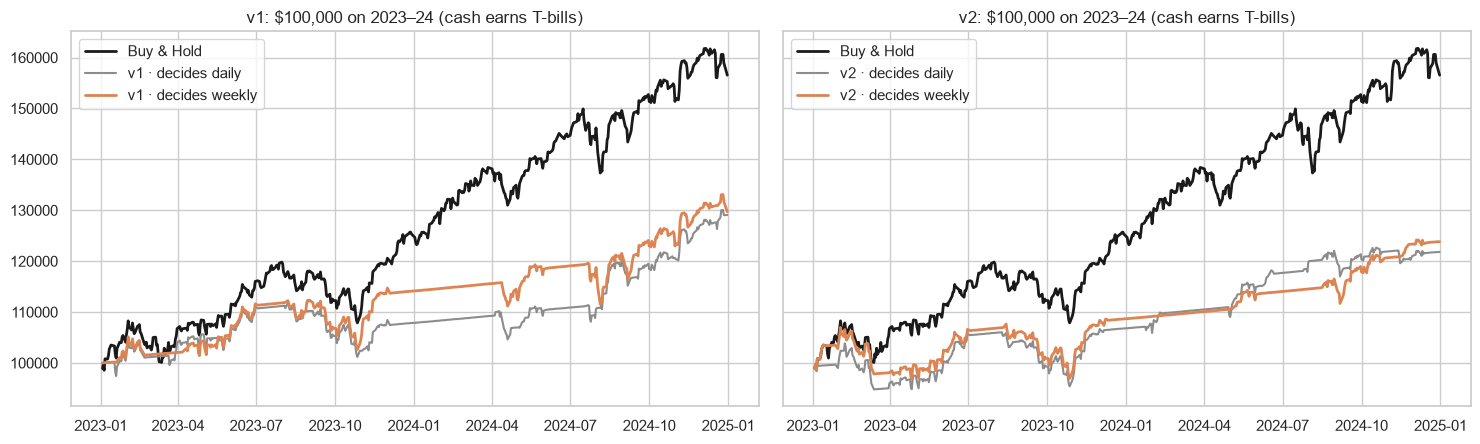

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for j, v in enumerate(["v1", "v2"]):
    cash = "0%" if v == "v1" else "T-bills"
    ax[j].plot(PATHS[("Buy & Hold", "2023–24 test", "—")], color="k", lw=2, label="Buy & Hold")
    ax[j].plot(PATHS[(v, "2023–24 test", "daily")], color="0.55", lw=1.5, label=f"{v} · decides daily")
    ax[j].plot(PATHS[(v, "2023–24 test", "weekly")], color="C1", lw=2, label=f"{v} · decides weekly")
    ax[j].set_title(f"{v}: $100,000 on 2023–24 (cash earns T-bills)"); ax[j].legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "daily_vs_weekly_2023_24.png", dpi=120, bbox_inches="tight"); plt.show()

## Details of the weekly strategy (2023–24 test and 2013–24 walk-forward; cash earns T-bills)
The figures the write-up and slides quote for the weekly schedule.

In [7]:
idx = pr.index                                   # 2023–24 test days (v1's saved predictions)
pt = px.loc[idx]; rft = rf.loc[idx]
o2o = px["Open"].pct_change().shift(-1).reindex(idx)   # open(d) -> open(d+1): the day a position is held
bh_sim = v2.simulate(v2.buy_and_hold_held(idx), pt, rft)

def details(held, label):
    sim = v2.simulate(held, pt, rft)
    attr = v2.out_of_market_attribution(held, px)
    longest = attr.sort_values("days", ascending=False).iloc[0].to_dict() if len(attr) else None
    out = {"final_value": float(sim["value"].iloc[-1]), "days": int(len(held)), "days_in": int(held.sum()),
           "avg_daily_when_in": float(o2o[held == 1].mean()), "avg_daily_when_out": float(o2o[held == 0].mean()),
           "missed_while_out": float((1 + o2o[held == 0].dropna()).prod() - 1),
           "costs": float(sim["fees"].sum()), "zero_fee_final": float(v2.simulate(held, pt, rft, fees=0.0)["value"].iloc[-1]),
           "max_drawdown": float((sim["value"] / sim["value"].cummax() - 1).min()),
           "longest_cash_spell": {k: str(v) for k, v in longest.items()} if longest else None,
           "path": [round(float(x)) for x in sim["value"]]}
    print(label, {k: v for k, v in out.items() if k != "path"})
    return out

w1 = details(v2.held_from_positions(weekly.weekly_positions_from_actions(pr["action"], start=0)), "v1 weekly")
held_w2 = v2.held_from_positions(weekly.weekly_positions_from_er(er2, "long"), start=1)
w2 = details(held_w2, "v2 weekly")
rand2 = v2.random_timing_benchmark(held_w2, pt, rft, n=1000)
w2["random_median_final"] = float(rand2.median())
w2["beats_random"] = float((rand2 < w2["final_value"]).mean())

# 2013–24 walk-forward, weekly v2: calendar-year returns vs Buy & Hold
held_wf = v2.held_from_positions(weekly.weekly_positions_from_er(er_wf, "long"), start=1)
v_wf = v2.simulate(held_wf, px.loc[er_wf.index], rf.loc[er_wf.index])["value"]
b_wf = v2.simulate(v2.buy_and_hold_held(er_wf.index), px.loc[er_wf.index], rf.loc[er_wf.index])["value"]
yr = pd.DataFrame({"v2": v_wf, "bh": b_wf})
yearly = yr.groupby(yr.index.year).apply(lambda g: g.iloc[-1] / g.iloc[0] - 1)
yearly["diff"] = yearly["v2"] - yearly["bh"]
display((yearly * 100).round(1))
DETAILS = {"dates": [d.strftime("%Y-%m-%d") for d in idx], "bh_path": [round(float(x)) for x in bh_sim["value"]],
           "v1_weekly": w1, "v2_weekly": w2,
           "v2_weekly_walk_forward_yearly": [{"year": int(y), "v2": float(r.v2), "bh": float(r.bh), "diff": float(r["diff"])} for y, r in yearly.iterrows()]}
(OUT / "details.json").write_text(json.dumps(DETAILS, indent=1))
print("years ahead of Buy & Hold:", int((yearly["diff"] > 0).sum()), "of", len(yearly))

v1 weekly {'final_value': 129705.21494389584, 'days': 502, 'days_in': 304, 'avg_daily_when_in': 0.0008379153404088338, 'avg_daily_when_out': 0.001108258489954822, 'missed_while_out': 0.23714505482557202, 'costs': 1256.3856650095142, 'zero_fee_final': 131139.78323692863, 'max_drawdown': -0.08657417296732339, 'longest_cash_spell': {'out_from': '2023-12-04', 'back_in': '2024-04-15', 'days': '90', 'spy_move': '0.1388'}}
v2 weekly {'final_value': 123833.54190255498, 'days': 502, 'days_in': 261, 'avg_daily_when_in': 0.000768350553833911, 'avg_daily_when_out': 0.0011366001441845024, 'missed_while_out': 0.30143739231727884, 'costs': 1987.7343321569529, 'zero_fee_final': 126082.72835689227, 'max_drawdown': -0.09937528490183878, 'longest_cash_spell': {'out_from': '2023-12-11', 'back_in': '2024-05-06', 'days': '100', 'spy_move': '0.1256'}}


,v2,bh,diff
Date,,,
2013,4.0000,29.0000,-25.0000
2014,10.0000,14.6000,-4.6000
2015,-6.0000,1.3000,-7.3000
2016,13.2000,13.6000,-0.3000
2017,8.0000,20.8000,-12.8000
2018,-6.6000,-5.2000,-1.4000
2019,24.8000,31.1000,-6.3000
2020,-22.6000,17.2000,-39.8000
2021,15.9000,30.5000,-14.6000


years ahead of Buy & Hold: 1 of 12


## Save

In [8]:
out = json.loads(res.to_json(orient="records"))
(OUT / "results.json").write_text(json.dumps(out, indent=2))
print("saved outputs/weekly/results.json and figures/")

saved outputs/weekly/results.json and figures/
